# Ames Housing

**Задача:** исследовать признаки, влияющие на цену продажи дома в Эймсе, и возможные сложности прогнозирования `SalePrice`.

**Источник:** [Kaggle House Prices - Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data). Исходный `train.csv` из архива Kaggle. Для запуска файл должен лежать рядом с ноутбуком. Описание признаков - `data_description.txt`. Использованы `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, типы столбцов, первые строки и сводная статистика. В `train.csv` значение `NA` читается как `NaN` для исследования пропусков, а строковая категория `None` сохраняется.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("train.csv", keep_default_na=False, na_values=["NA"])
print("Размер:", df.shape)
print("Типы столбцов:", df.dtypes.value_counts().to_dict())
display(df.head())

Размер: (1460, 81)
Типы столбцов: {<StringDtype(storage='python', na_value=nan)>: 43, dtype('int64'): 35, dtype('float64'): 3}


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
display(df.describe(include="all").T.round(2))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
...,...,...,...,...,...,...,...,...,...,...,...
MoSold,1460.0,NaN,NaN,NaN,6.321918,2.703626,1.0,5.0,6.0,8.0,12.0
YrSold,1460.0,NaN,NaN,NaN,2007.815753,1.328095,2006.0,2007.0,2008.0,2009.0,2010.0
SaleType,1460,9,WD,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1460,6,Normal,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


В таблице 1 460 строк и 81 столбец: идентификатор `Id`, 79 входных признаков и таргет `SalePrice`. Среди входных признаков 36 числовых и 43 строковых. Часть числовых столбцов, например `MSSubClass` и `MoSold`, обозначает категории или календарные коды.

## 2. Таргет

`SalePrice` - цена продажи дома в долларах США. Исходная постановка - регрессия.

In [3]:
print(df["SalePrice"].describe().round(2))
print("Асимметрия:", round(df["SalePrice"].skew(), 3))
print("Нулевых или отрицательных цен:", int(df["SalePrice"].le(0).sum()))

count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
Асимметрия: 1.883
Нулевых или отрицательных цен: 0


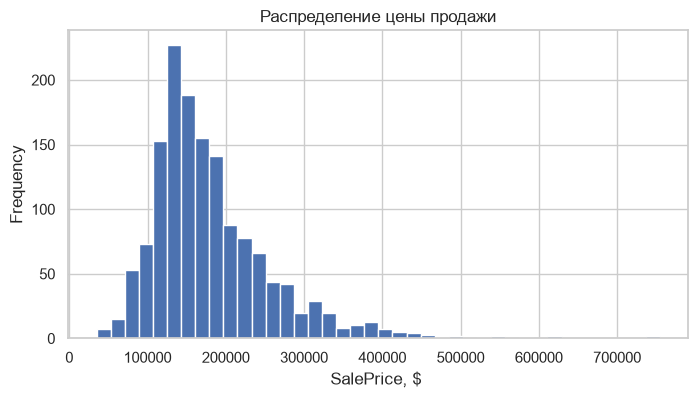

In [4]:
df["SalePrice"].plot.hist(bins=40, figsize=(8, 4))
plt.title("Распределение цены продажи")
plt.xlabel("SalePrice, $ ")
plt.show()

Цена находится в диапазоне от 34 900 до 755 000 долларов, медиана - 163 000, среднее - 180 921,20. Асимметрия распределения составляет 1,883. Нулевых и отрицательных значений нет.

## 3. Пропуски и специальные значения

В `train.csv` отсутствующие или неприменимые значения обозначены `NA`. При чтении они распознаются как `NaN`. По `data_description.txt` для ряда признаков `NA` означает отсутствие объекта: например, гаража, бассейна или камина.

In [5]:
missing = pd.DataFrame({"NaN": df.isna().sum(),
                        "NaN, %": (df.isna().mean() * 100).round(2)})
display(missing.loc[missing["NaN"] > 0].sort_values("NaN", ascending=False))
print("Всего NaN:", int(df.isna().sum().sum()))
print("Доля входных ячеек, %:", round(df.isna().sum().sum() / (len(df) * 79) * 100, 2))
print("Столбцов с NaN:", int(df.isna().any().sum()))
print("Строк с NaN:", int(df.isna().any(axis=1).sum()))
print("Полностью заполненных строк:", int(df.notna().all(axis=1).sum()))

,NaN,"NaN, %"
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageCond,81,5.55
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Всего NaN: 6965
Доля входных ячеек, %: 6.04
Столбцов с NaN: 19
Строк с NaN: 1460
Полностью заполненных строк: 0


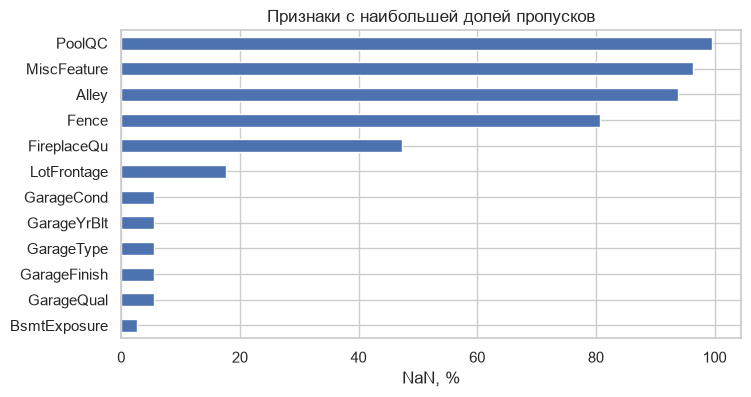

In [6]:
missing.loc[missing["NaN"] > 0, "NaN, %"].sort_values().tail(12).plot.barh(figsize=(8, 4))
plt.title("Признаки с наибольшей долей пропусков")
plt.xlabel("NaN, %")
plt.show()

In [7]:
for count_col, category_col in [("Fireplaces", "FireplaceQu"),
                                ("GarageCars", "GarageType"),
                                ("PoolArea", "PoolQC"),
                                ("TotalBsmtSF", "BsmtQual")]:
    print(category_col, "NaN:", int(df[category_col].isna().sum()),
          "из них при нулевом", count_col + ":",
          int((df[category_col].isna() & df[count_col].eq(0)).sum()))
print("MasVnrType = None:", int(df["MasVnrType"].eq("None").sum()))
print("MasVnrType = NaN:", int(df["MasVnrType"].isna().sum()))

FireplaceQu NaN: 690 из них при нулевом Fireplaces: 690
GarageType NaN: 81 из них при нулевом GarageCars: 81
PoolQC NaN: 1453 из них при нулевом PoolArea: 1453
BsmtQual NaN: 37 из них при нулевом TotalBsmtSF: 37
MasVnrType = None: 864
MasVnrType = NaN: 8


После чтения 6 965 значений `NA` представлены как `NaN` (6,04% ячеек входных признаков). Пропуски встречаются в 19 столбцах и во всех 1 460 строках. Наибольшие доли - `PoolQC` (1 453; 99,52%), `MiscFeature` (1 406; 96,30%), `Alley` (1 369; 93,77%) и `Fence` (1 179; 80,75%).

Пропуски в `FireplaceQu`, `GarageType`, `PoolQC` и `BsmtQual` полностью совпадают с отсутствием соответствующего объекта по количественному показателю: 690, 81, 1 453 и 37 строк. Это структурные пропуски. В `MasVnrType` отдельно встречаются строковая категория `None` (864) и восемь `NaN`.

## 4. Дубликаты и проверка диапазонов

Проверяются идентификаторы, правдоподобность числовых величин и согласованность годов.

In [8]:
print("Полные дубликаты:", int(df.duplicated().sum()))
print("Повторы Id:", int(df["Id"].duplicated().sum()))
print("Повторы входных признаков без Id:", int(df.drop(columns=["Id", "SalePrice"]).duplicated().sum()))
print("Неположительные LotArea / GrLivArea / SalePrice:",
      int(df[["LotArea", "GrLivArea", "SalePrice"]].le(0).sum().sum()))
print("YearBuilt > YrSold:", int(df["YearBuilt"].gt(df["YrSold"]).sum()))
print("YearRemodAdd > YrSold:", int(df["YearRemodAdd"].gt(df["YrSold"]).sum()))
print("GarageYrBlt > YrSold:", int(df["GarageYrBlt"].gt(df["YrSold"]).sum()))
print("MoSold вне 1-12:", int((~df["MoSold"].between(1, 12)).sum()))
display(df.loc[df["YearRemodAdd"].gt(df["YrSold"]),
               ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "MoSold", "SalePrice"]])

Полные дубликаты: 0
Повторы Id: 0
Повторы входных признаков без Id: 0
Неположительные LotArea / GrLivArea / SalePrice: 0
YearBuilt > YrSold: 0
YearRemodAdd > YrSold: 1
GarageYrBlt > YrSold: 0
MoSold вне 1-12: 0


,Id,YearBuilt,YearRemodAdd,YrSold,MoSold,SalePrice
523,524,2007,2008,2007,10,184750


Полных дубликатов, повторов `Id` и одинаковых наборов входных признаков без `Id` нет. Неположительных площадей `LotArea`, `GrLivArea` и цен также нет. В одной строке `YearRemodAdd` больше `YrSold`.

## 5. Числовые распределения и выбросы

Для площадей и цен исследуются распределения. IQR используется только как предварительный сигнал о необычных значениях.

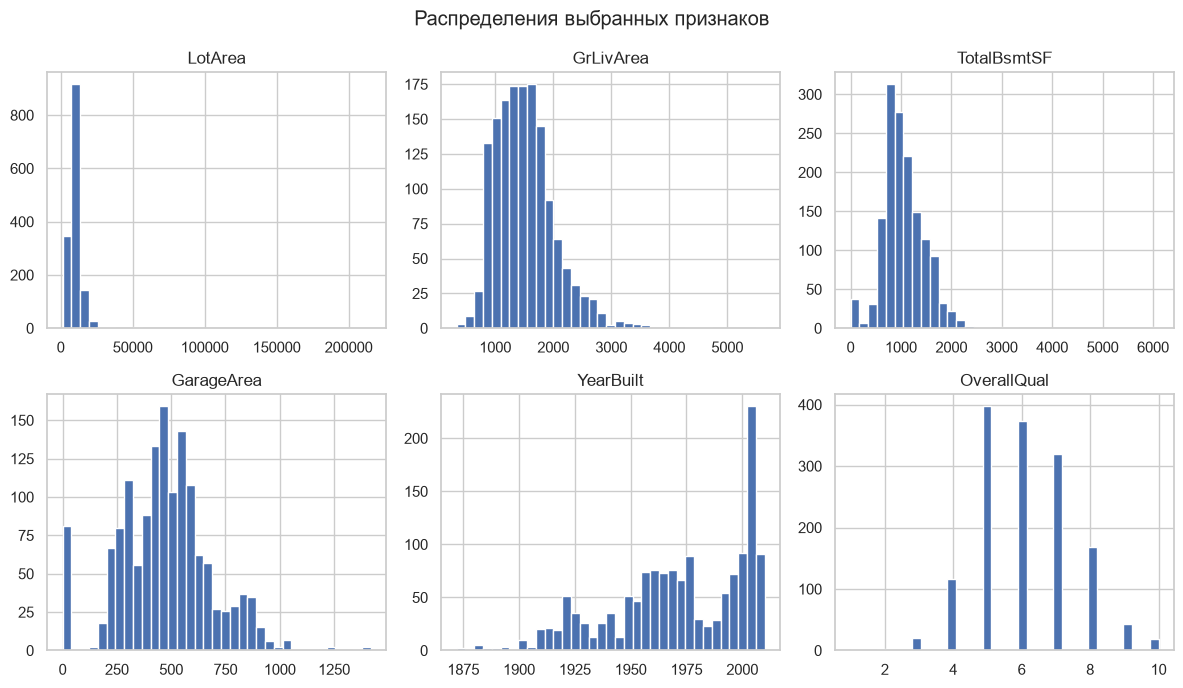

In [9]:
num_cols = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "OverallQual"]
df[num_cols].hist(bins=35, figsize=(12, 7), layout=(2, 3))
plt.suptitle("Распределения выбранных признаков")
plt.tight_layout()
plt.show()

In [11]:
for col in ["SalePrice", "LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    flags = s.lt(q1 - 1.5 * (q3 - q1)) | s.gt(q3 + 1.5 * (q3 - q1))
    print(col, "медиана:", s.median(), "IQR:", int(flags.sum()),
          f"({flags.mean() * 100:.2f}%)")

SalePrice медиана: 163000.0 IQR: 61 (4.18%)
LotArea медиана: 9478.5 IQR: 69 (4.73%)
GrLivArea медиана: 1464.0 IQR: 31 (2.12%)
TotalBsmtSF медиана: 991.5 IQR: 61 (4.18%)
GarageArea медиана: 480.0 IQR: 21 (1.44%)


In [12]:
print("Площадь GrLivArea > 4000:", int(df["GrLivArea"].gt(4000).sum()))
display(df.loc[df["GrLivArea"].gt(4000),
               ["Id", "GrLivArea", "OverallQual", "SalePrice"]])
print("Нулевых GarageArea:", int(df["GarageArea"].eq(0).sum()))
print("Нулевых TotalBsmtSF:", int(df["TotalBsmtSF"].eq(0).sum()))

Площадь GrLivArea > 4000: 4


,Id,GrLivArea,OverallQual,SalePrice
523,524,4676,10,184750
691,692,4316,10,755000
1182,1183,4476,10,745000
1298,1299,5642,10,160000


Нулевых GarageArea: 81
Нулевых TotalBsmtSF: 37


По правилу 1,5 IQR отмечены 61 значение `SalePrice` (4,18%), 69 значений `LotArea` (4,73%), 31 значение `GrLivArea` (2,12%), 61 значение `TotalBsmtSF` (4,18%) и 21 значение `GarageArea` (1,44%).

Для `GrLivArea > 4000` обнаружены четыре дома. У двух из них цены 184 750 и 160 000 долларов при очень большой площади. Это необычные сочетания для дальнейшей проверки, но оснований удалять строки нет. Нулевые `GarageArea` (81) и `TotalBsmtSF` (37) соответствуют отсутствию этих объектов.

## 6. Категориальные признаки и связь с таргетом

Для всех строковых полей вычисляются размеры категорий и число уникальных значений. Для отдельных категорий сравниваются медианы цен.

In [13]:
cats = df.select_dtypes(exclude="number").columns
cat_summary = pd.DataFrame({"Категорий": df[cats].nunique(),
                            "Пропусков": df[cats].isna().sum(),
                            "Частая категория": df[cats].mode().iloc[0],
                            "Частота, %": (df[cats].apply(lambda s: s.value_counts(dropna=True).iloc[0])
                                            / len(df) * 100).round(2)})
display(cat_summary)

,Категорий,Пропусков,Частая категория,"Частота, %"
MSZoning,5,0,RL,78.84
Street,2,0,Pave,99.59
Alley,2,1369,Grvl,3.42
LotShape,4,0,Reg,63.36
LandContour,4,0,Lvl,89.79
Utilities,2,0,AllPub,99.93
LotConfig,5,0,Inside,72.05
LandSlope,3,0,Gtl,94.66
Neighborhood,25,0,NAmes,15.41
Condition1,9,0,Norm,86.30


In [14]:
for col in ["Neighborhood", "ExterQual", "KitchenQual", "SaleCondition"]:
    print(col)
    grouped = df.groupby(col, dropna=False)["SalePrice"].agg(строк="size", медиана="median")
    display(grouped.sort_values("строк", ascending=False).head(12))
print("OverallQual")
display(df.groupby("OverallQual")["SalePrice"].agg(строк="size", медиана="median"))

Neighborhood


,строк,медиана
Neighborhood,,
NAmes,225,140000.0
CollgCr,150,197200.0
OldTown,113,119000.0
Edwards,100,121750.0
Somerst,86,225500.0
Gilbert,79,181000.0
NridgHt,77,315000.0
Sawyer,74,135000.0
NWAmes,73,182900.0


ExterQual


,строк,медиана
ExterQual,,
TA,906,139450.0
Gd,488,220000.0
Ex,52,364606.5
Fa,14,82250.0


KitchenQual


,строк,медиана
KitchenQual,,
TA,735,137000.0
Gd,586,201400.0
Ex,100,316750.0
Fa,39,115000.0


SaleCondition


,строк,медиана
SaleCondition,,
Normal,1198,160000.0
Partial,125,244600.0
Abnorml,101,130000.0
Family,20,140500.0
Alloca,12,148145.0
AdjLand,4,104000.0


OverallQual


,строк,медиана
OverallQual,,
1,2,50150.0
2,3,60000.0
3,20,86250.0
4,116,108000.0
5,397,133000.0
6,374,160000.0
7,319,200141.0
8,168,269750.0
9,43,345000.0


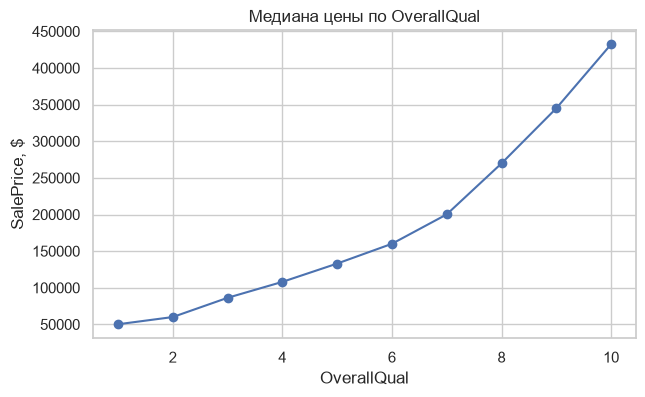

In [15]:
grade = df.groupby("OverallQual")["SalePrice"].median()
grade.plot(marker="o", figsize=(7, 4))
plt.title("Медиана цены по OverallQual")
plt.ylabel("SalePrice, $")
plt.show()

Медиана `SalePrice` различается по качеству дома: при `OverallQual = 5` - 133 000 долларов (397 домов), при `OverallQual = 10` - 432 390 долларов (18 домов). В `Neighborhood` также есть различия: `OldTown` - 119 000 долларов (113 домов), `NridgHt` - 315 000 долларов (77 домов).

## 7. Числовые корреляции и парные графики

Для корреляций исключены `Id` и числовые категориальные коды `MSSubClass`, `MoSold`, `YrSold`. `OverallQual` остаётся как порядковая оценка качества.

In [16]:
numeric = df.select_dtypes(include="number").drop(columns=["Id", "MSSubClass", "MoSold", "YrSold"])
correlations = numeric.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print("Связь с SalePrice:")
print(correlations.round(3).to_string())

Связь с SalePrice:
OverallQual      0.791
GrLivArea        0.709
GarageCars       0.640
GarageArea       0.623
TotalBsmtSF      0.614
1stFlrSF         0.606
FullBath         0.561
TotRmsAbvGrd     0.534
YearBuilt        0.523
YearRemodAdd     0.507
GarageYrBlt      0.486
MasVnrArea       0.477
Fireplaces       0.467
BsmtFinSF1       0.386
LotFrontage      0.352
WoodDeckSF       0.324
2ndFlrSF         0.319
OpenPorchSF      0.316
HalfBath         0.284
LotArea          0.264
BsmtFullBath     0.227
BsmtUnfSF        0.214
BedroomAbvGr     0.168
ScreenPorch      0.111
PoolArea         0.092
3SsnPorch        0.045
BsmtFinSF2      -0.011
BsmtHalfBath    -0.017
MiscVal         -0.021
LowQualFinSF    -0.026
OverallCond     -0.078
EnclosedPorch   -0.129
KitchenAbvGr    -0.136


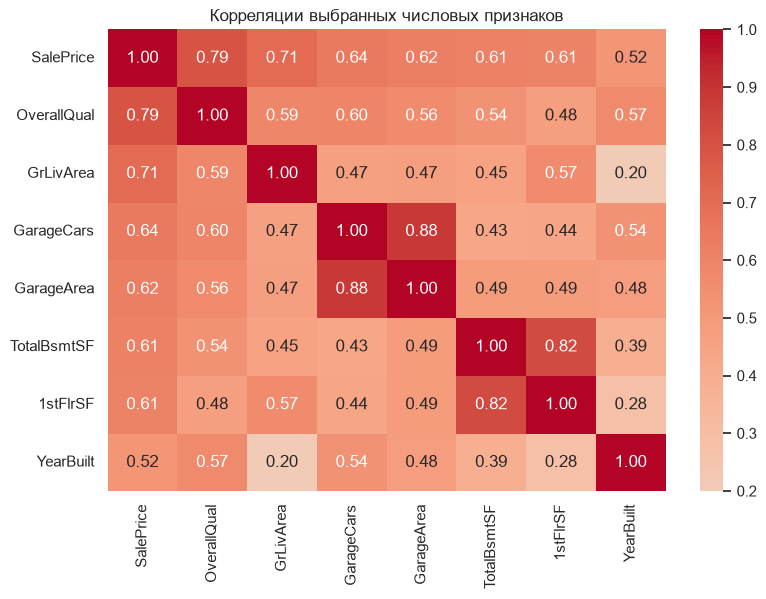

In [17]:
selected = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars",
            "GarageArea", "TotalBsmtSF", "1stFlrSF", "YearBuilt"]
plt.figure(figsize=(9, 6))
sns.heatmap(df[selected].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции выбранных числовых признаков")
plt.show()

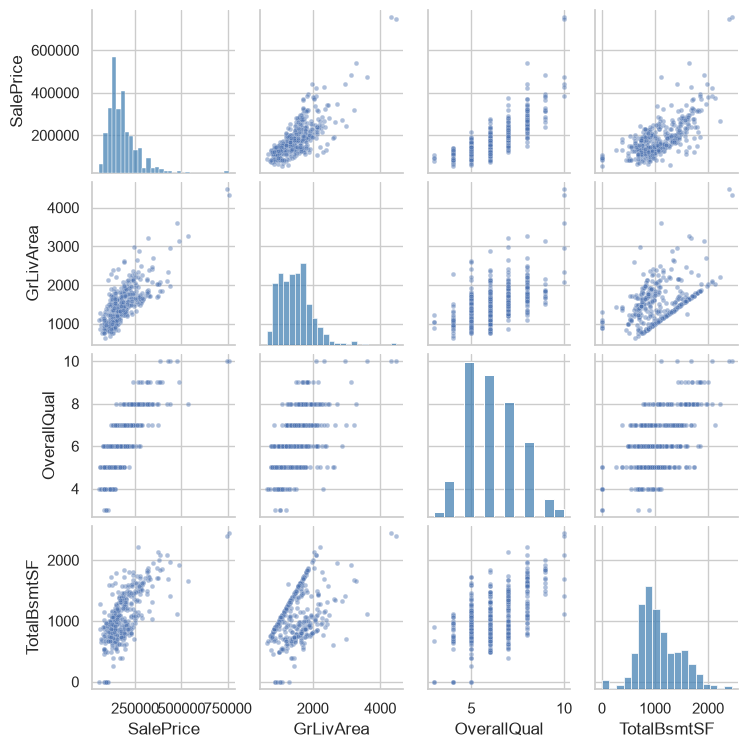

In [18]:
sample = df[["SalePrice", "GrLivArea", "OverallQual", "TotalBsmtSF"]].sample(400, random_state=7)
sns.pairplot(sample, diag_kind="hist", height=1.9,
             plot_kws={"alpha": 0.45, "s": 12}, diag_kws={"color": "steelblue"})
plt.show()

In [19]:
for first, second in [("GarageCars", "GarageArea"),
                      ("GrLivArea", "TotRmsAbvGrd"),
                      ("1stFlrSF", "TotalBsmtSF")]:
    print(first, second, round(df[first].corr(df[second]), 3))

GarageCars GarageArea 0.882
GrLivArea TotRmsAbvGrd 0.825
1stFlrSF TotalBsmtSF 0.82


С `SalePrice` наиболее заметны корреляции `OverallQual` (0,791), `GrLivArea` (0,709), `GarageCars` (0,640), `GarageArea` (0,623) и `TotalBsmtSF` (0,614). Среди входных признаков связаны `GarageCars` и `GarageArea` (0,882), `GrLivArea` и `TotRmsAbvGrd` (0,825), `1stFlrSF` и `TotalBsmtSF` (0,820). Эти коэффициенты показывают линейные связи.

## 8. Временная структура

`YrSold` и `MoSold` обозначают год и месяц продажи. День и точное время сделки отсутствуют.

In [20]:
print("Год продажи")
display(df.groupby("YrSold")["SalePrice"].agg(строк="size", медиана="median", среднее="mean").round(2))
print("Месяц продажи")
display(df.groupby("MoSold")["SalePrice"].agg(строк="size", медиана="median").round(2))

Год продажи


,строк,медиана,среднее
YrSold,,,
2006,314,163995.0,182549.46
2007,329,167000.0,186063.15
2008,304,164000.0,177360.84
2009,338,162000.0,179432.10
2010,175,155000.0,177393.67


Месяц продажи


,строк,медиана
MoSold,,
1,58,151650.0
2,52,173250.0
3,106,165250.0
4,141,147000.0
5,204,154000.0
6,253,163000.0
7,234,165195.0
8,122,174450.0
9,63,185900.0


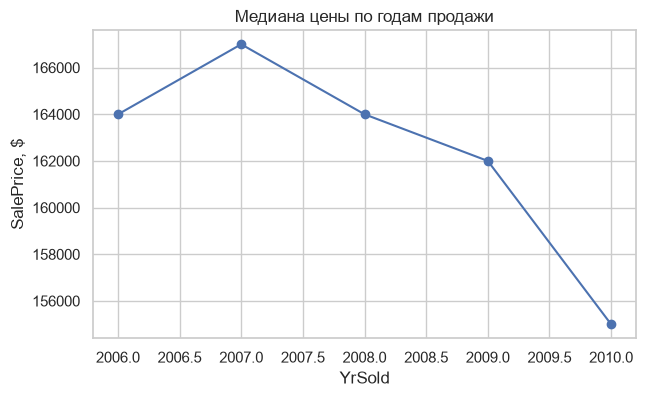

In [21]:
df.groupby("YrSold")["SalePrice"].median().plot(marker="o", figsize=(7, 4))
plt.title("Медиана цены по годам продажи")
plt.ylabel("SalePrice, $")
plt.show()

Продажи в файле относятся к 2006-2010 годам. Наблюдений по годам соответственно 314, 329, 304, 338 и 175. Медианная цена в 2006 году - 163 995 долларов, в 2010 году - 155 000. Сравнение не отделяет изменение рынка от изменения состава проданных домов. Год и месяц позволяют приблизительно упорядочить периоды.

## 9. Выводы и эталон для агента

1. **Цель:** `SalePrice` - цена продажи дома. Исходная постановка - регрессия.
2. **Пропуски:** различать структурное отсутствие гаража, бассейна или подвала и неизвестное значение. Не объединять категорию `None` с `NaN`.
3. **Идентификатор:** `Id` не использовать как содержательный признак.
4. **Типы:** `MSSubClass`, `MoSold`, `YrSold` интерпретировать по смыслу.
5. **Необычные значения:** проверить крупные площади, низкие цены при большой площади и несогласованный `YearRemodAdd`. Не удалять строки по одному правилу IQR.
6. **Момент прогноза:** уточнить, какие характеристики и условия продажи известны до сделки. Проверить доступность `SaleType`, `SaleCondition`, `YrSold`, `MoSold`.
7. **Метрика:** MAE или RMSE для оценки абсолютных ошибок в стоимости домов. RMSE по логарифмам цен можно использовать, если важнее относительная величина ошибки.
8. **Валидация:** при проверке переноса на будущие сделки учитывать `YrSold` и `MoSold`. Точного порядка внутри месяца нет.

## Как воспроизвести

Открыть `ames_housing.ipynb` в VS Code или Jupyter, установить `pandas`, `matplotlib`, `seaborn` и выполнить ячейки сверху вниз. Рядом с ноутбуком должен лежать исходный `train.csv`. Описание полей - `data_description.txt`.